<a href="https://colab.research.google.com/github/DIRECT0R-ctrl/Bankly/blob/main/diagnostic_multimodal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Data.zip to Data.zip


In [8]:
import zipfile
from pathlib import Path

zip_path = "/content/Data.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [10]:
from pathlib import Path

root = Path("./Data")

for path in list(root.iterdir()):
    print(path.name)

meningioma
glioma
pituitary
notumor


Charger les images, vérifier extensions et intégrité (try-except), écarter les fichiers invalides.


In [13]:
import cv2

def load_images(folder_path):

    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

    images = []
    rejected_files = []

    folder = Path(folder_path)

    for file_path in folder.rglob("*"):

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in valid_extensions:
            continue

        try:
            image = cv2.imread(str(file_path))

            if image is None:
                rejected_files.append(str(file_path))
                continue

            images.append((str(file_path), image))

        except Exception as error:
            print(f"Error loading {file_path}: {error}")
            rejected_files.append(str(file_path))

    return images, rejected_files

In [15]:
images, rejected_files = load_images("./Data")

print("Successfully loaded:", len(images))
print("Rejected files:", len(rejected_files))

Successfully loaded: 7023
Rejected files: 0


Explorer les classes (noms de dossiers), countplot, afficher un échantillon par classe.

In [16]:
for file_path in images[:5]:
  print(file_path)

('Data/meningioma/Tr-me_0176.jpg', array([[[5, 5, 5],
        [5, 5, 5],
        [5, 5, 5],
        ...,
        [7, 7, 7],
        [7, 7, 7],
        [7, 7, 7]],

       [[5, 5, 5],
        [5, 5, 5],
        [5, 5, 5],
        ...,
        [7, 7, 7],
        [7, 7, 7],
        [7, 7, 7]],

       [[5, 5, 5],
        [5, 5, 5],
        [5, 5, 5],
        ...,
        [7, 7, 7],
        [7, 7, 7],
        [7, 7, 7]],

       ...,

       [[4, 4, 4],
        [4, 4, 4],
        [5, 5, 5],
        ...,
        [5, 5, 5],
        [5, 5, 5],
        [5, 5, 5]],

       [[5, 5, 5],
        [5, 5, 5],
        [5, 5, 5],
        ...,
        [5, 5, 5],
        [5, 5, 5],
        [5, 5, 5]],

       [[5, 5, 5],
        [5, 5, 5],
        [5, 5, 5],
        ...,
        [5, 5, 5],
        [5, 5, 5],
        [5, 5, 5]]], dtype=uint8))
('Data/meningioma/Tr-me_0558.jpg', array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],



In [17]:
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the class name from each image's path
class_names = [
    Path(file_path).parent.name
    for file_path, image in images
]

# Count images in each class
class_counts = Counter(class_names)

print("Classes found:", list(class_counts.keys()))
print("\nImages per class:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Classes found: ['meningioma', 'glioma', 'pituitary', 'notumor']

Images per class:
meningioma: 1645
glioma: 1621
pituitary: 1757
notumor: 2000


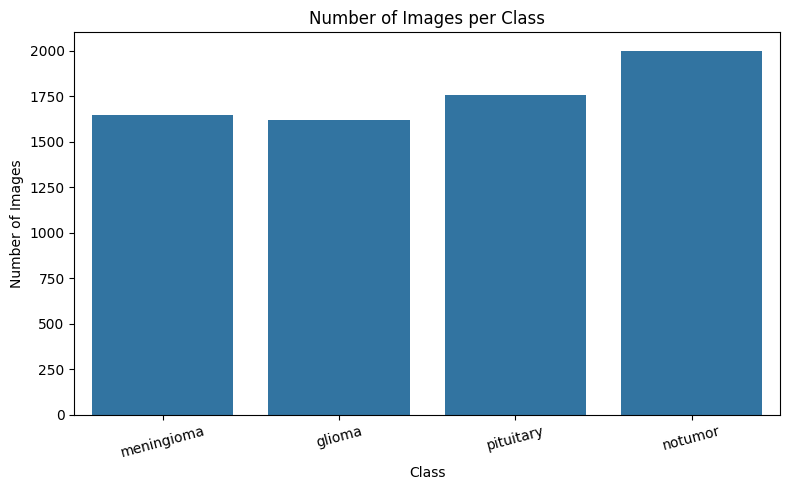

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=class_names,
    order=list(class_counts.keys())
)

plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

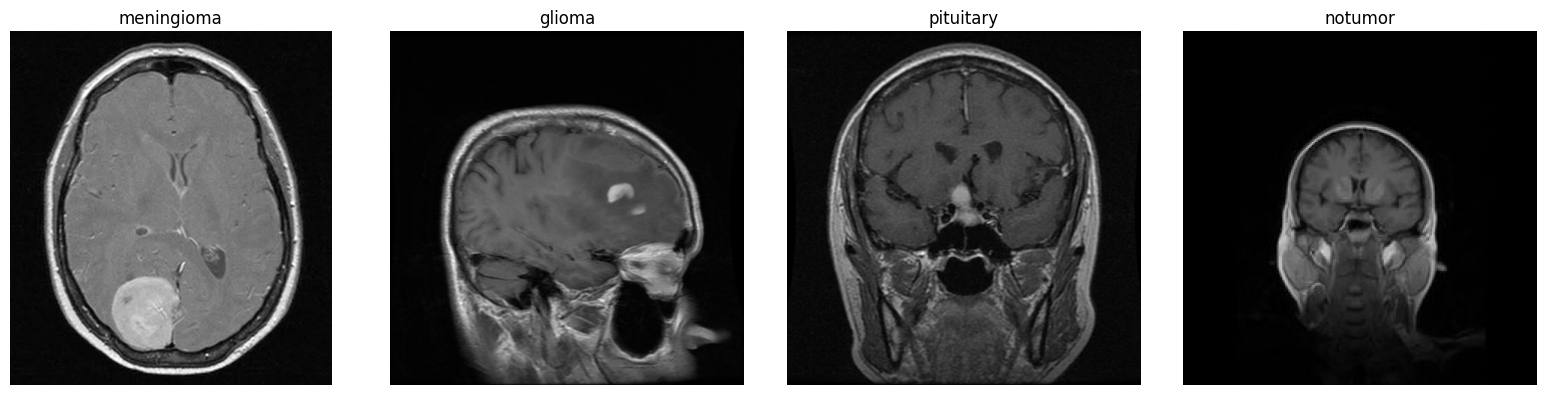

In [19]:
import matplotlib.pyplot as plt

# Create one subplot for each class
fig, axes = plt.subplots(1, len(class_counts), figsize=(16, 4))

for ax, class_name in zip(axes, class_counts.keys()):

    # Find the first image belonging to this class
    for file_path, image in images:
        if Path(file_path).parent.name == class_name:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            ax.set_title(class_name)
            ax.axis("off")
            break

plt.tight_layout()
plt.show()